# Find and Remove Instances of Pressure Fluctuations Due to Platelet Ice Formation

Craven et al. (2014) reports sporadic pressure decreases believed to be associated with frazil accretion and platelet ice formation, which increases the buoyancy of the moorings. Whether transient or permanent (where the uppermost instrument has become lodged in the base of the ice shelf (Craven et al., 2014)), such pressure fluctuations can affect the longer-term consistency of data recordings.

## Add Qualitatively Decided Time Windows 

Decisions corresponding to each event will be allocated 0, 1, or 2: \
0 - no action \
1 - remove upper cat data for timestamps in the event period \
2 - remove upper cat data for all timestamps after the commencement of the event period.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

position_colours = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

def plot_time_series(df, am_id, ylim_temp=None, ylim_sal=None, ylim_p=None, year=None):
    # Sort through dataframe keys and extract the keys containing the specified borehole is (AMXX)
    df_bh = df[df["borehole"] == am_id]

    # Filter to time range if specified
    df_bh = df_bh[(df_bh["time"].dt.year == year)]
        
    # Sort cats by median pressure to ensure consistent ordering across plots
    median_pressure = df_bh.groupby("cat")["pressure"].median().sort_values()
    cats = median_pressure.index.tolist()

    fig, (axT, axS, axP) = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

    for i, cat_id in enumerate(cats):
        dfp = df_bh[df_bh["cat"] == cat_id]
        colour = position_colours[i]

        axT.plot(dfp["time"], dfp["in_situ_temperature"], lw=0.8, label=f"cat{cat_id}", color=colour)
        axS.plot(dfp["time"], dfp["practical_salinity"],    lw=0.8, label=f"cat{cat_id}", color=colour)
        axP.plot(dfp["time"], dfp["pressure"],    lw=0.8, label=f"cat{cat_id}", color=colour)

    axT.set_ylabel("In Situ Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    axP.set_ylabel("Pressure (dbar)")
    #axS.set_xlabel("Year")
    axT.set_title(f"{am_id} MicroCAT: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)
    axP.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)
    if ylim_p  is not None: axP.set_ylim(*ylim_p)

    axT.grid(True); axS.grid(True); axP.grid(True)
    plt.tight_layout()
    plt.show()

events = []

df = pd.read_parquet("/g/data/gv90/ad6790/amery-amisor/data/proc/02_converted.parquet")

## AM01

### Visually Inspect CTD Changes

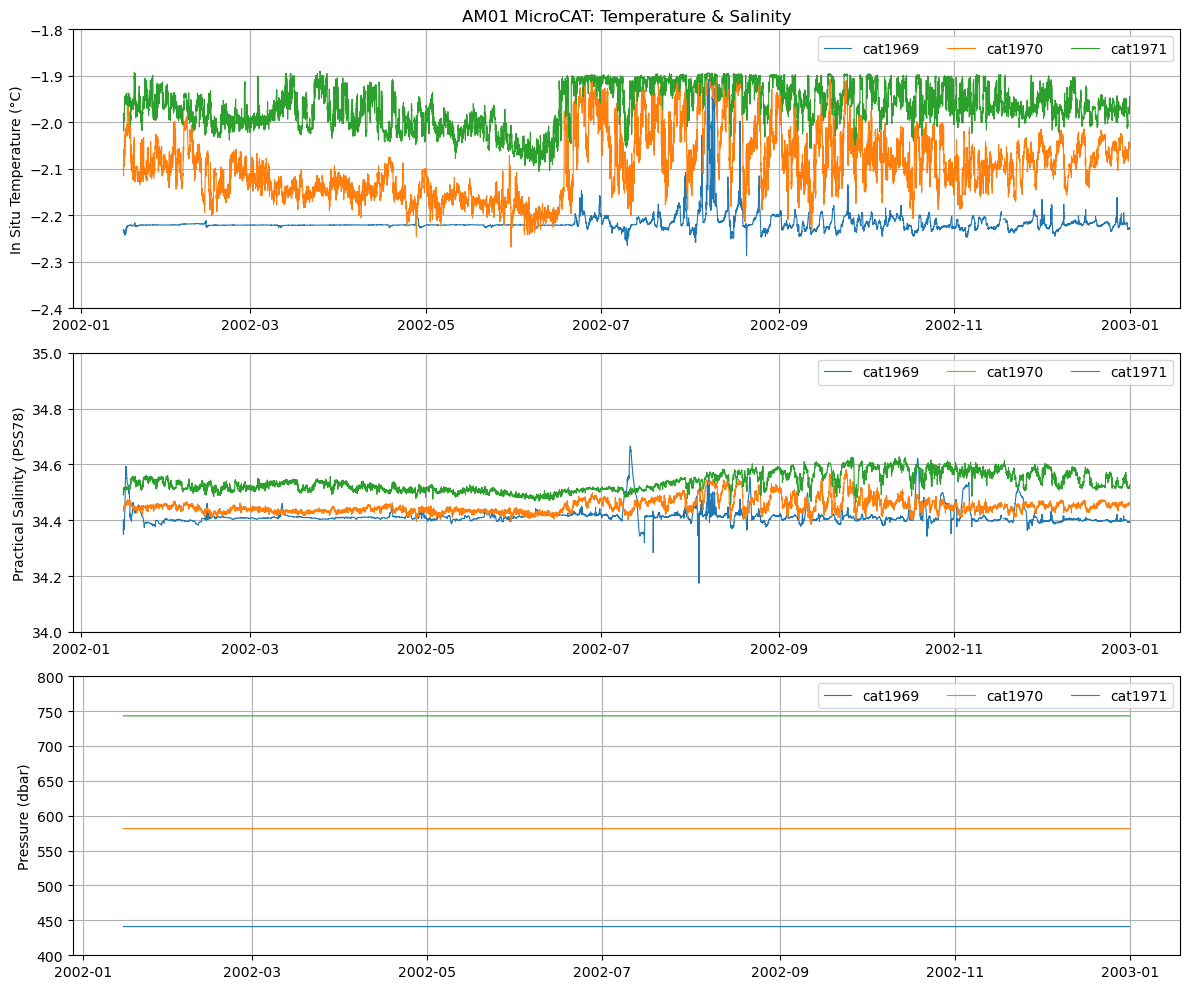

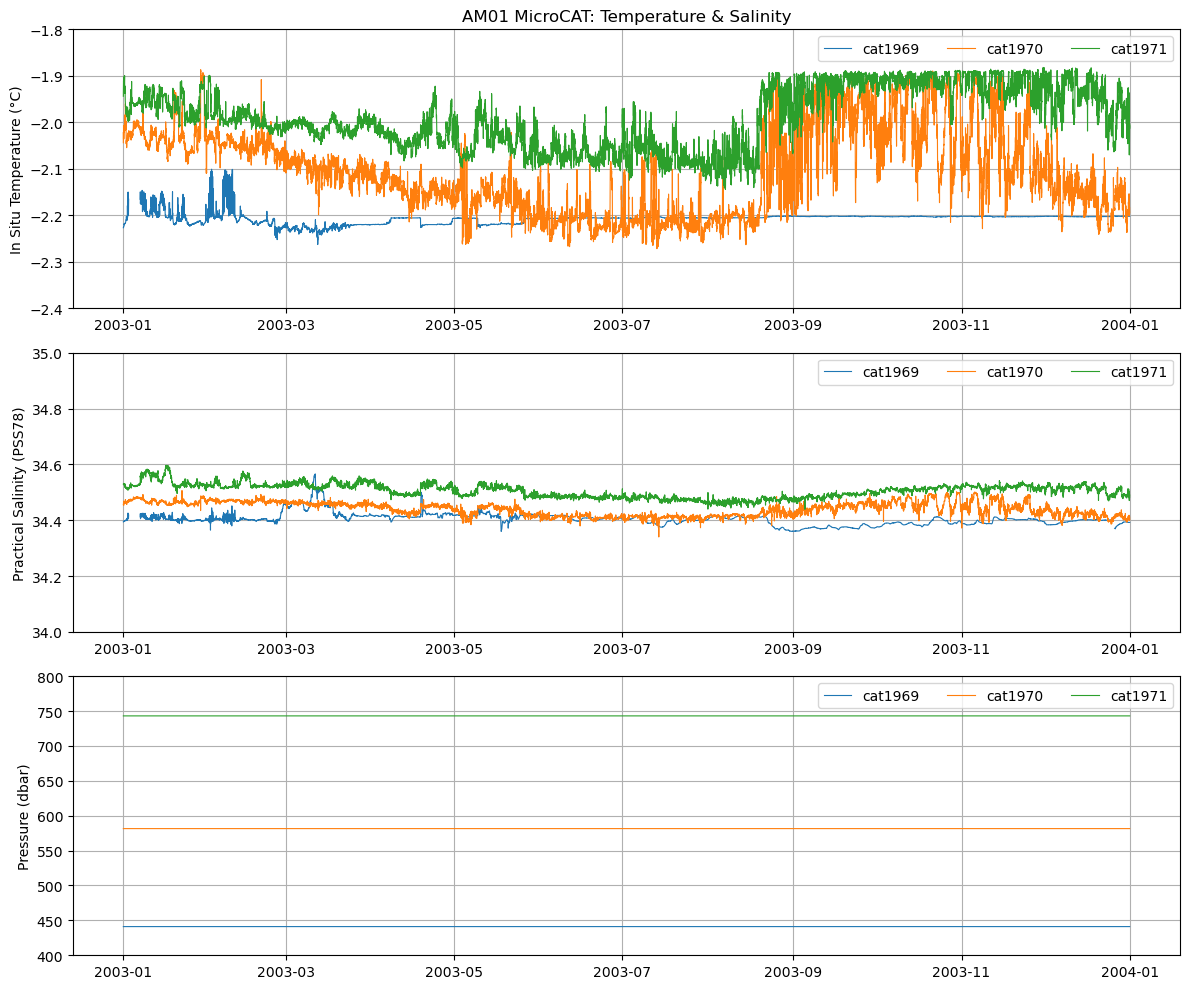

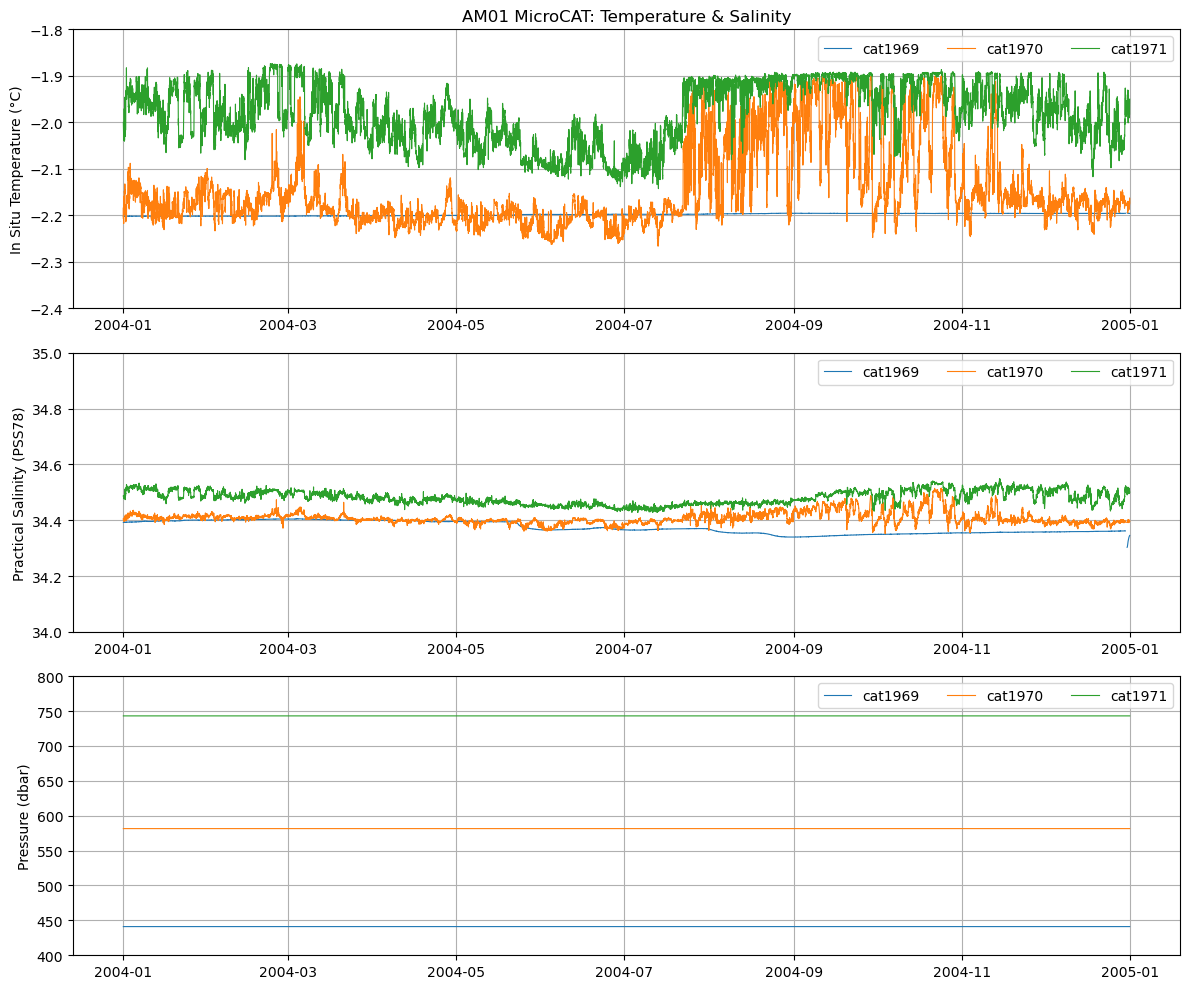

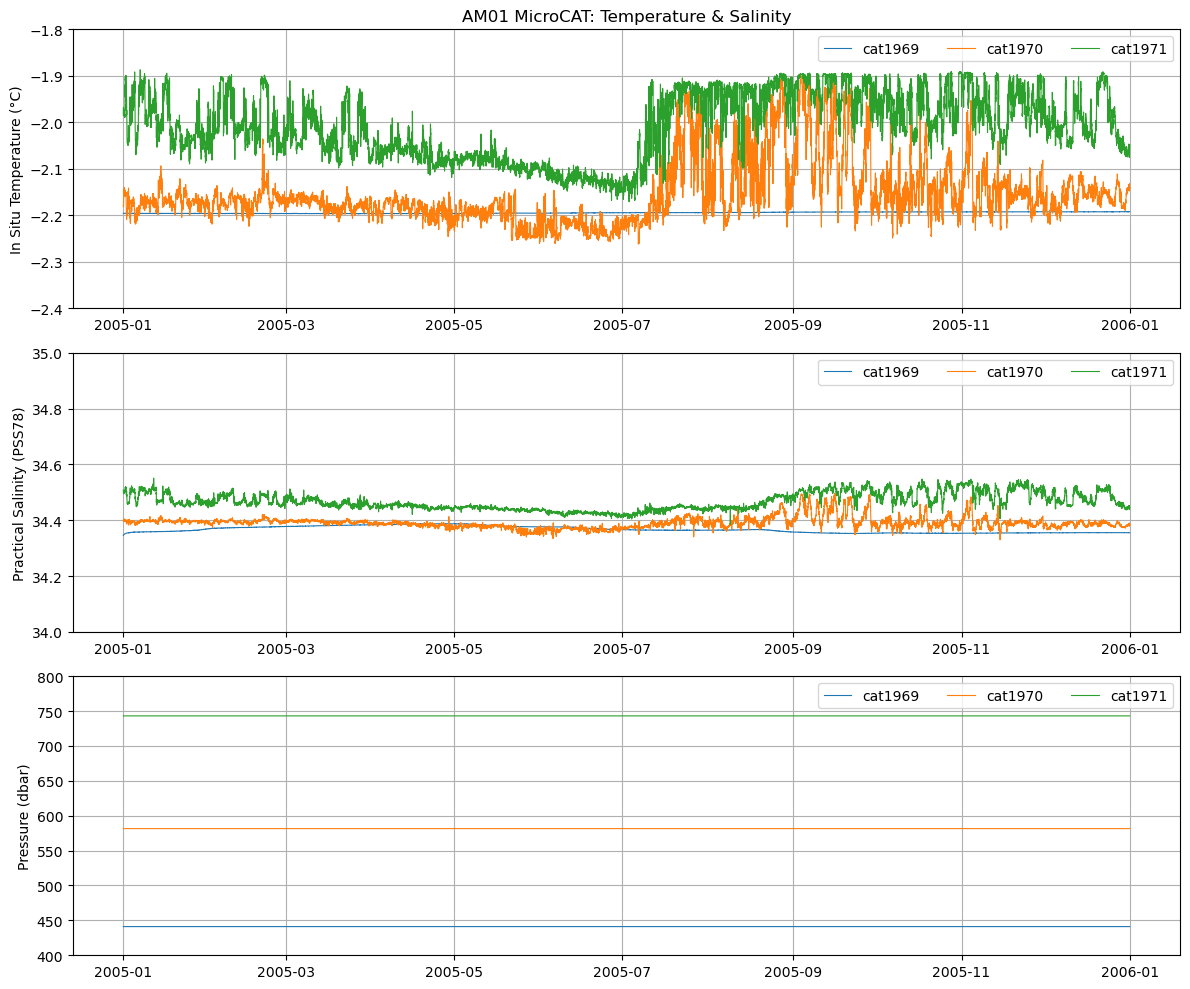

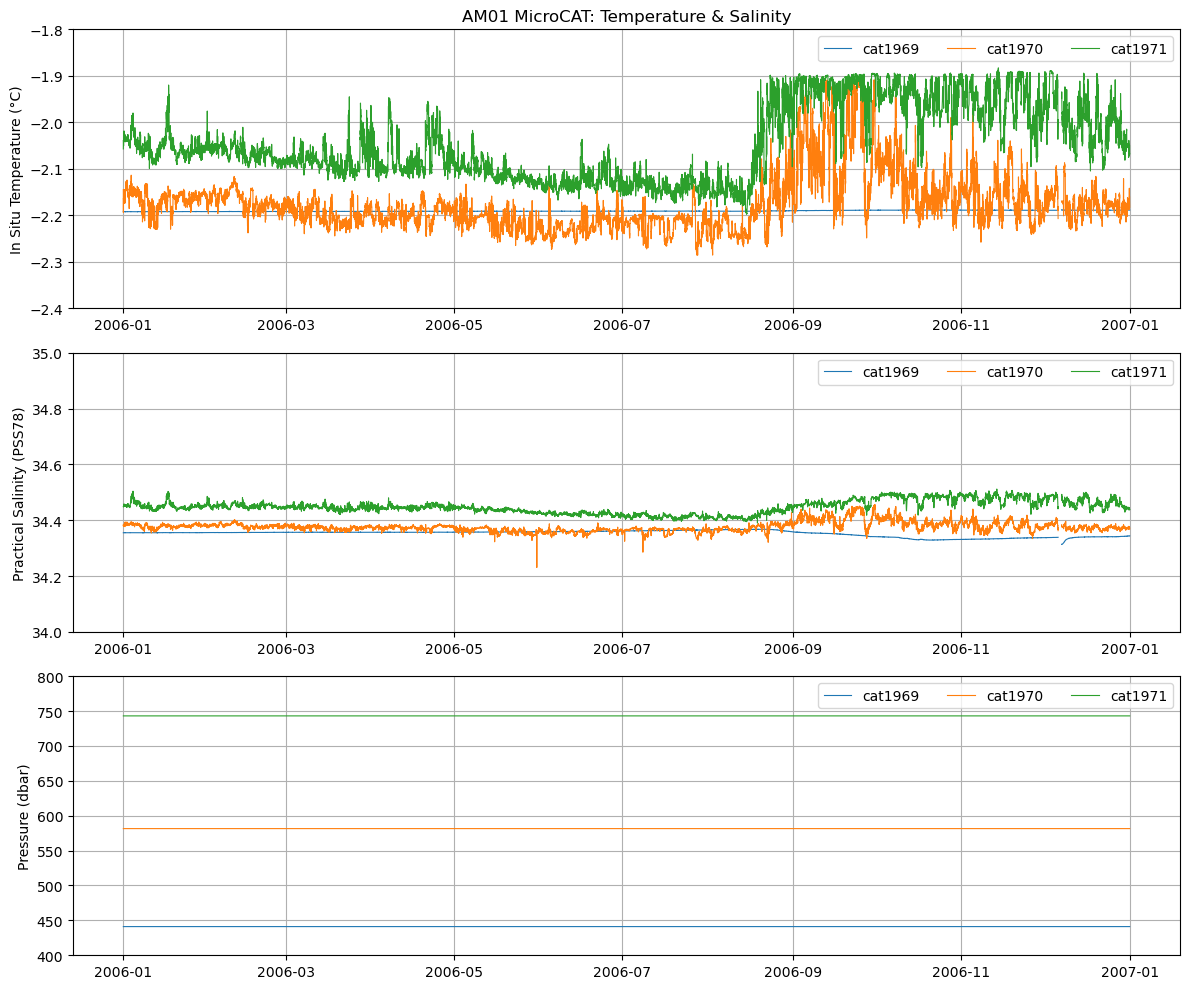

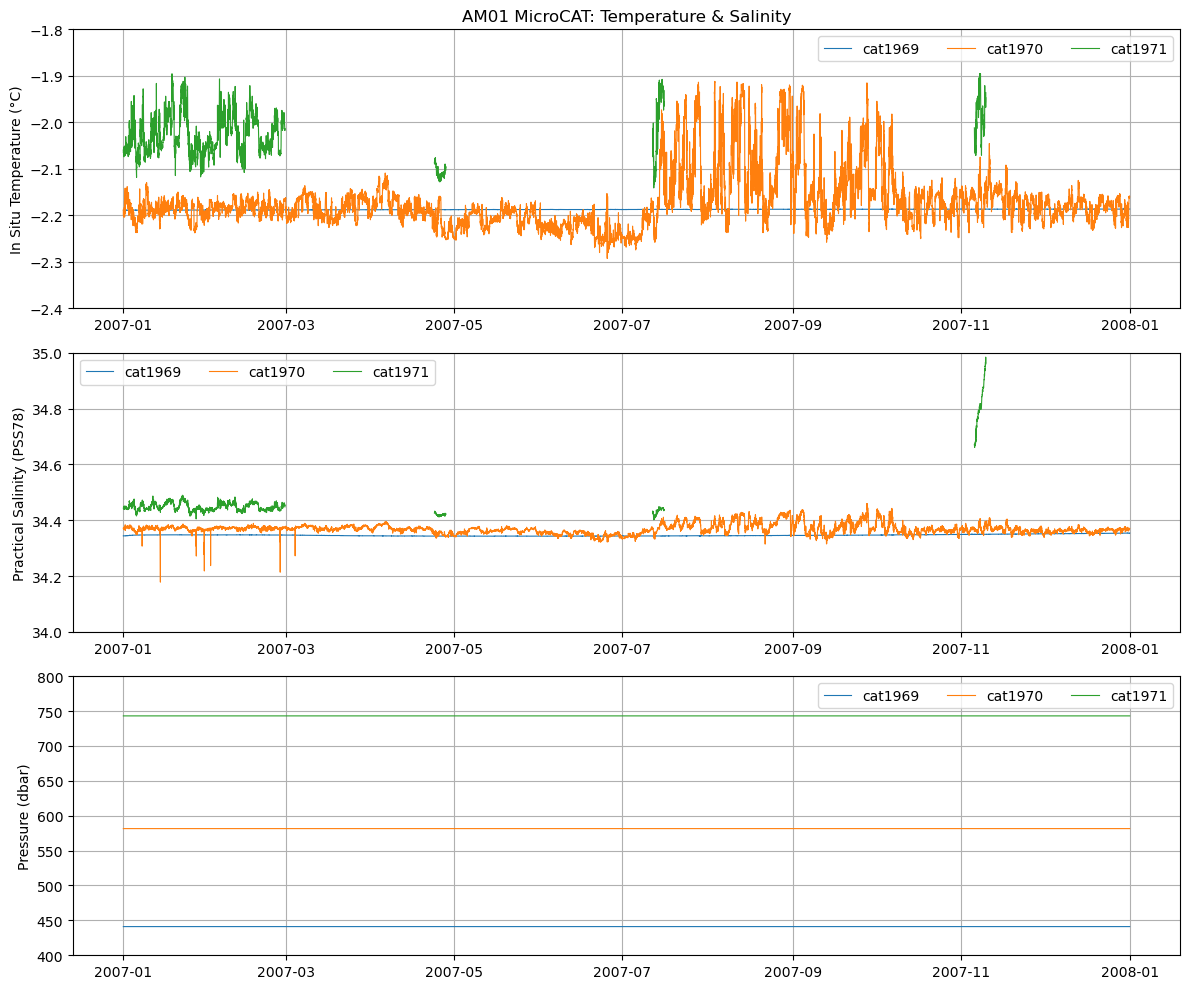

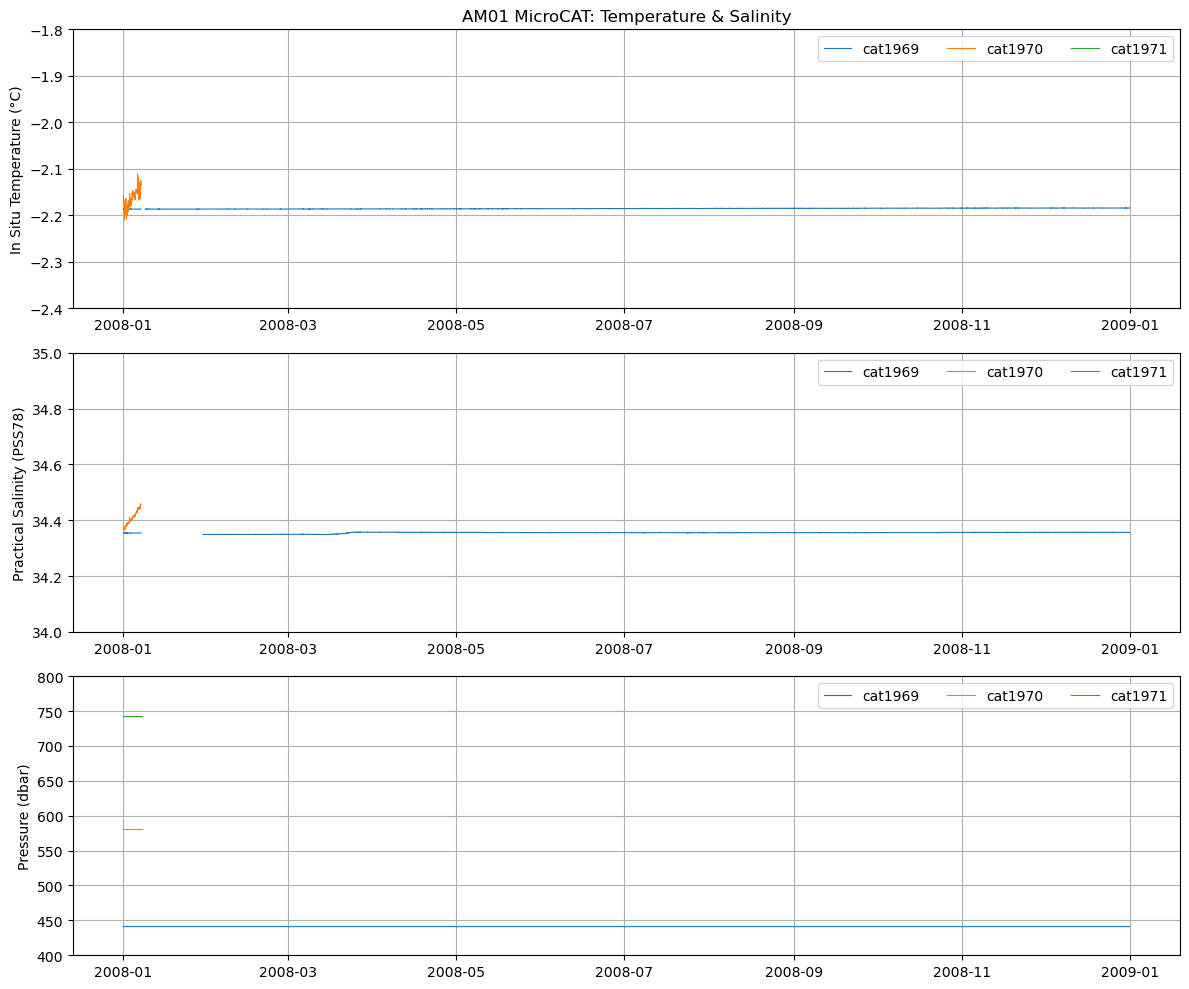

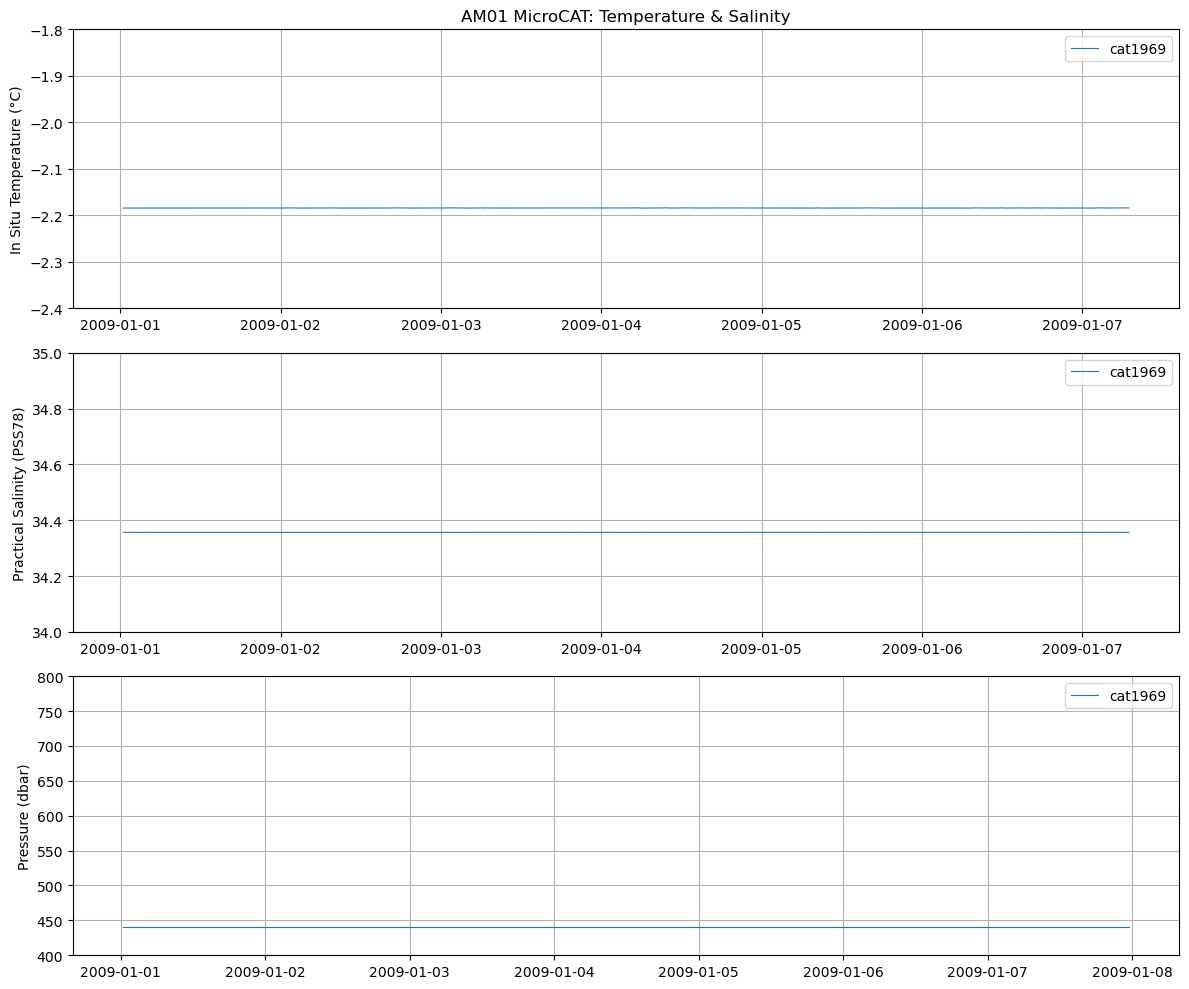

In [12]:
bh = "AM01"

for year in df[df["borehole"] == bh]["time"].dt.year.unique():
    plot_time_series(df, bh, (-2.4, -1.8), (34, 35), (400, 800), year)

### Add Pressure Events

Since all three pressure sensors at AM01 did not work for the entirety of the data collection period, much of these tabulated events are attributed to work done by Craven et al. (2014), who were able to access some of the raw pressure sensor data which did reveal pressure fluctuations. The conclusions of Craven et al. (2014) are complemented by visual inspection of temperature and salinity data here.

In [13]:
# February 2002 transient pressure change event
events.append({"borehole": bh, "event_start": "2002-02-03 00:00:00", "transition_end": "2002-02-12 00:00:00", "event_end": "2002-02-12 00:00:00", "reversion": True, "notes": "no evident impact", "decision": "1"})

# April 2002 transient pressure change event
events.append({"borehole": bh, "event_start": "2002-04-27 00:00:00", "transition_end": "2002-04-29 00:00:00", "event_end": "2002-04-29 00:00:00", "reversion": True, "notes": "clear impact on T", "decision": "1"})

# June 2002 transient pressure change event
events.append({"borehole": bh, "event_start": "2002-06-07 00:00:00", "transition_end": "2002-06-09 00:00:00", "event_end": "2002-06-09 00:00:00", "reversion": True, "notes": "no evident impact", "decision": "1"})

# April 2003 transient pressure change event
events.append({"borehole": bh, "event_start": "2003-04-05 00:00:00", "transition_end": "2003-04-10 00:00:00", "event_end": "2003-04-21 00:00:00", "reversion": True, "notes": "clear impact on T", "decision": "1"})

# April-May 2003 transient pressure change event
events.append({"borehole": bh, "event_start": "2003-04-27 00:00:00", "transition_end": "2003-04-29 00:00:00", "event_end": "2003-05-08 00:00:00", "reversion": True, "notes": "clear impact on T", "decision": "1"})

# May 2003 transient pressure change event
events.append({"borehole": bh, "event_start": "2003-05-25 00:00:00", "transition_end": "2003-05-30 00:00:00", "event_end": np.nan, "reversion": True, "notes": "clear impact on T", "decision": "2"})

## AM04

### Visually Inspect CTD Changes

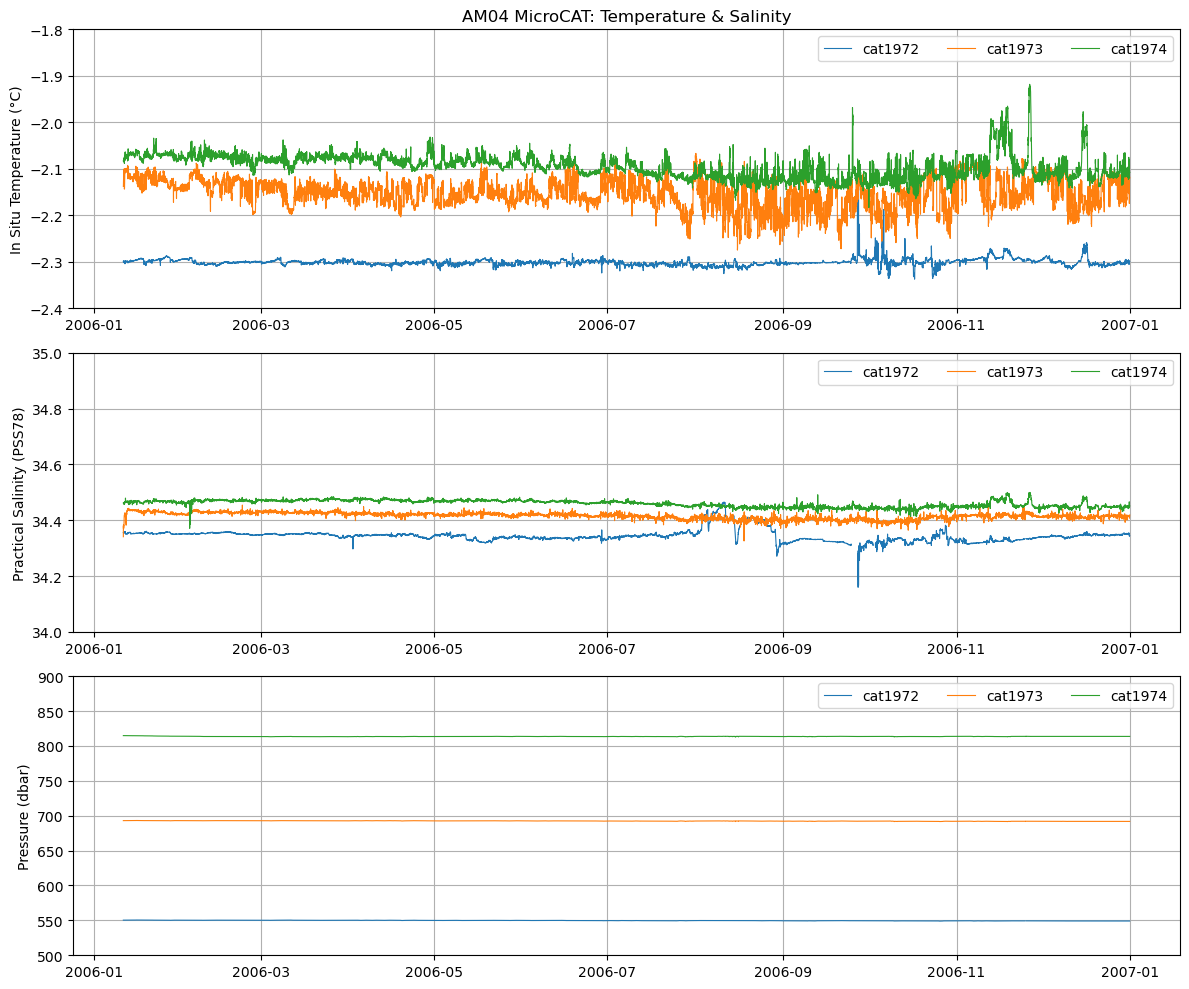

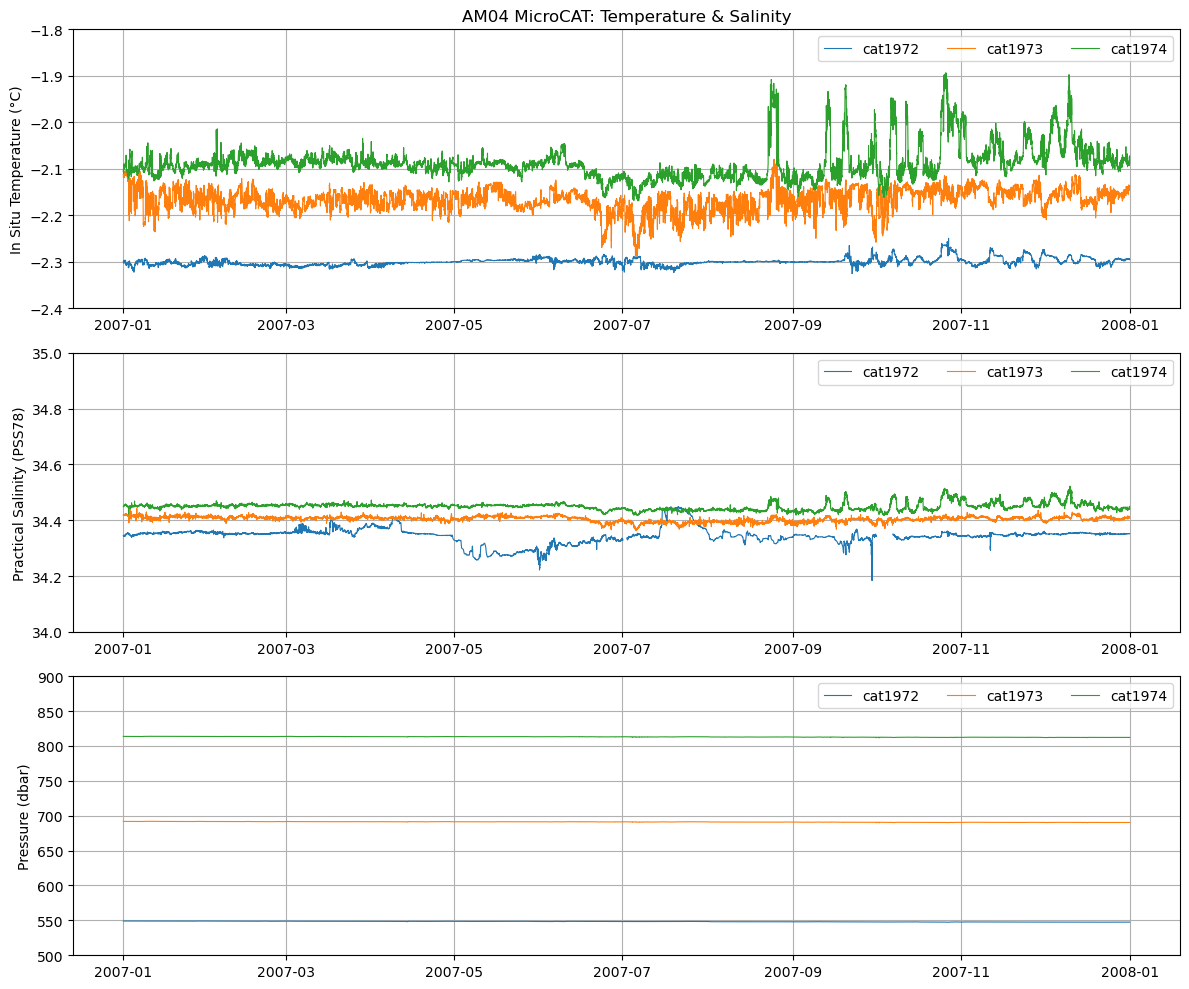

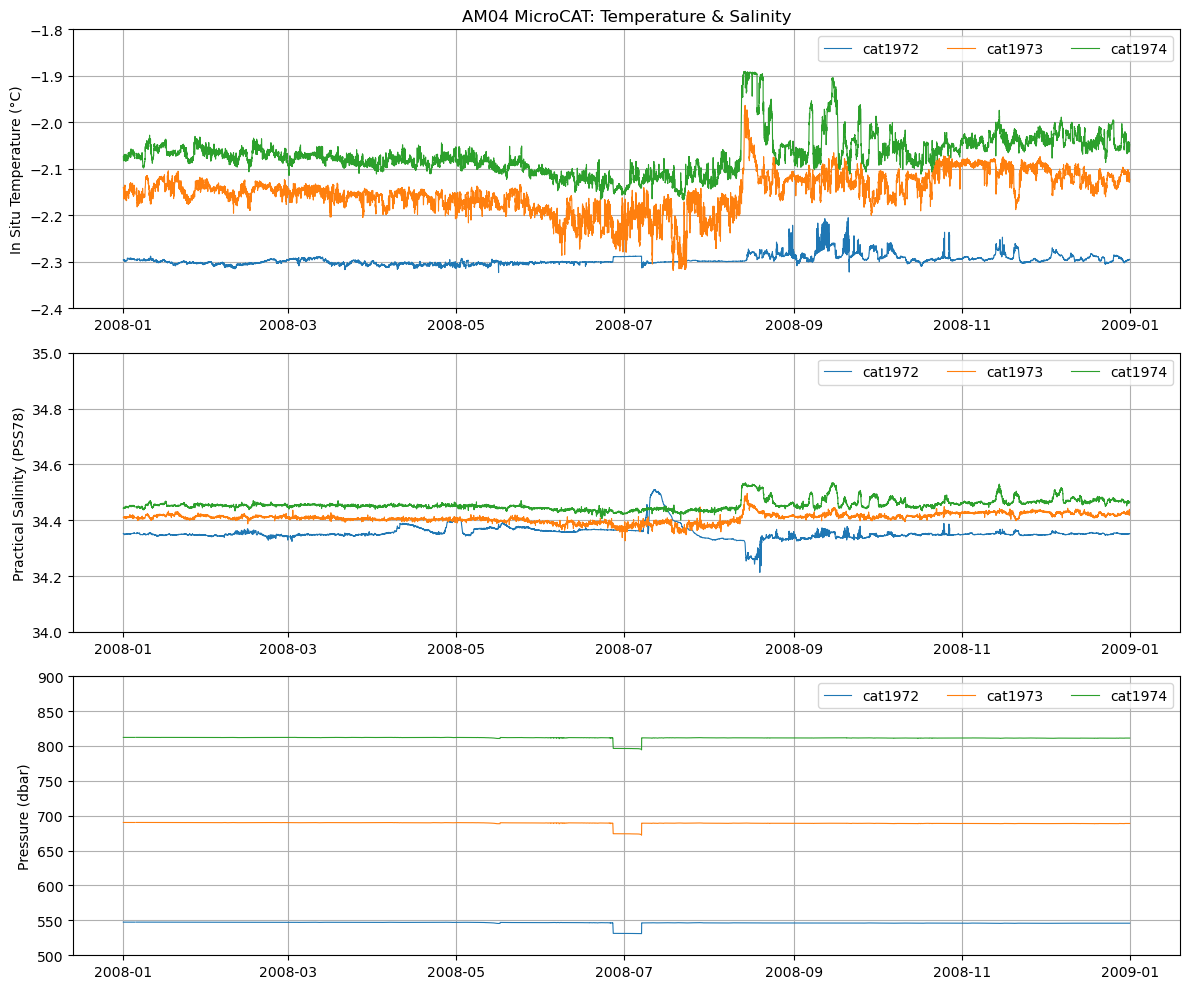

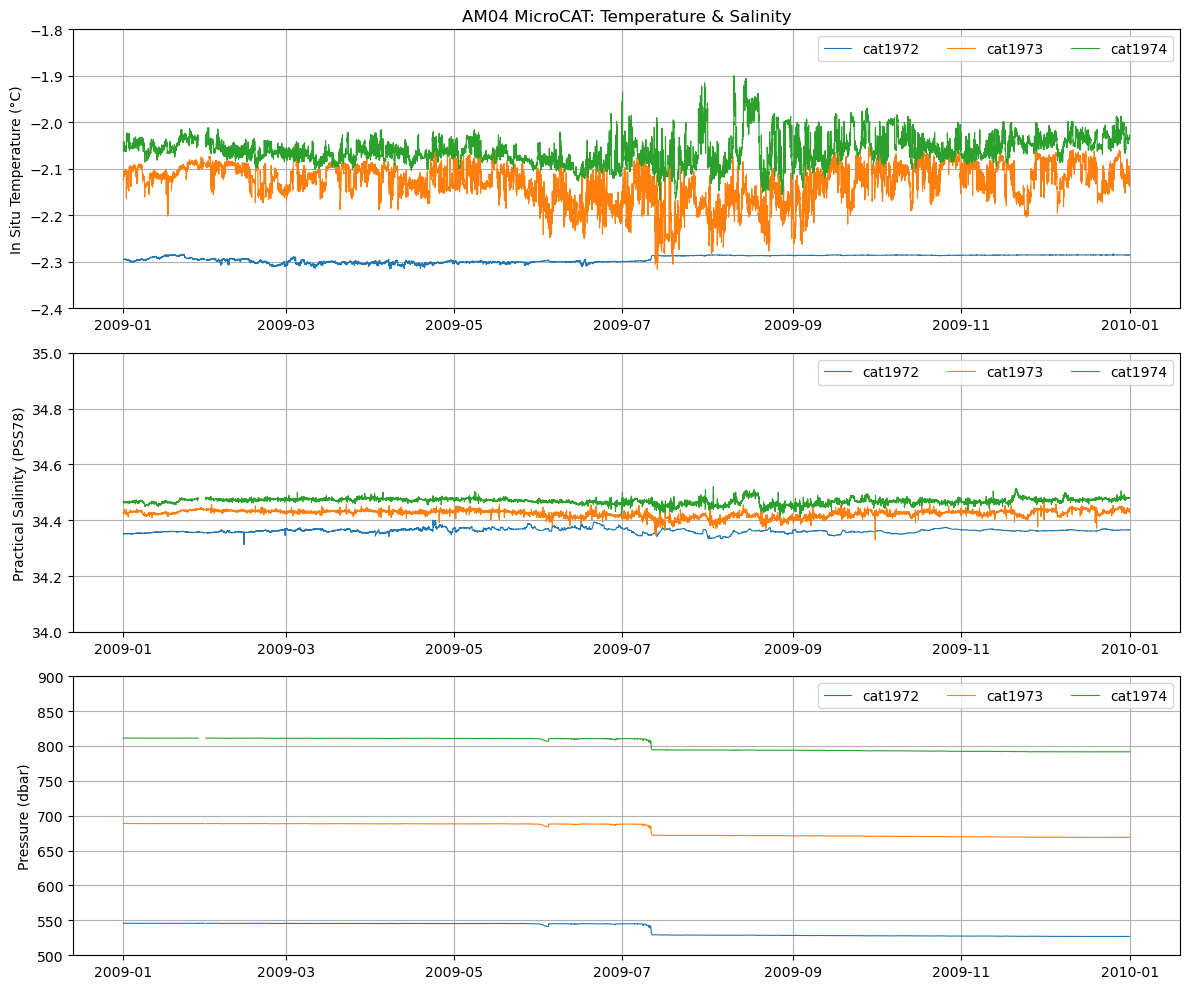

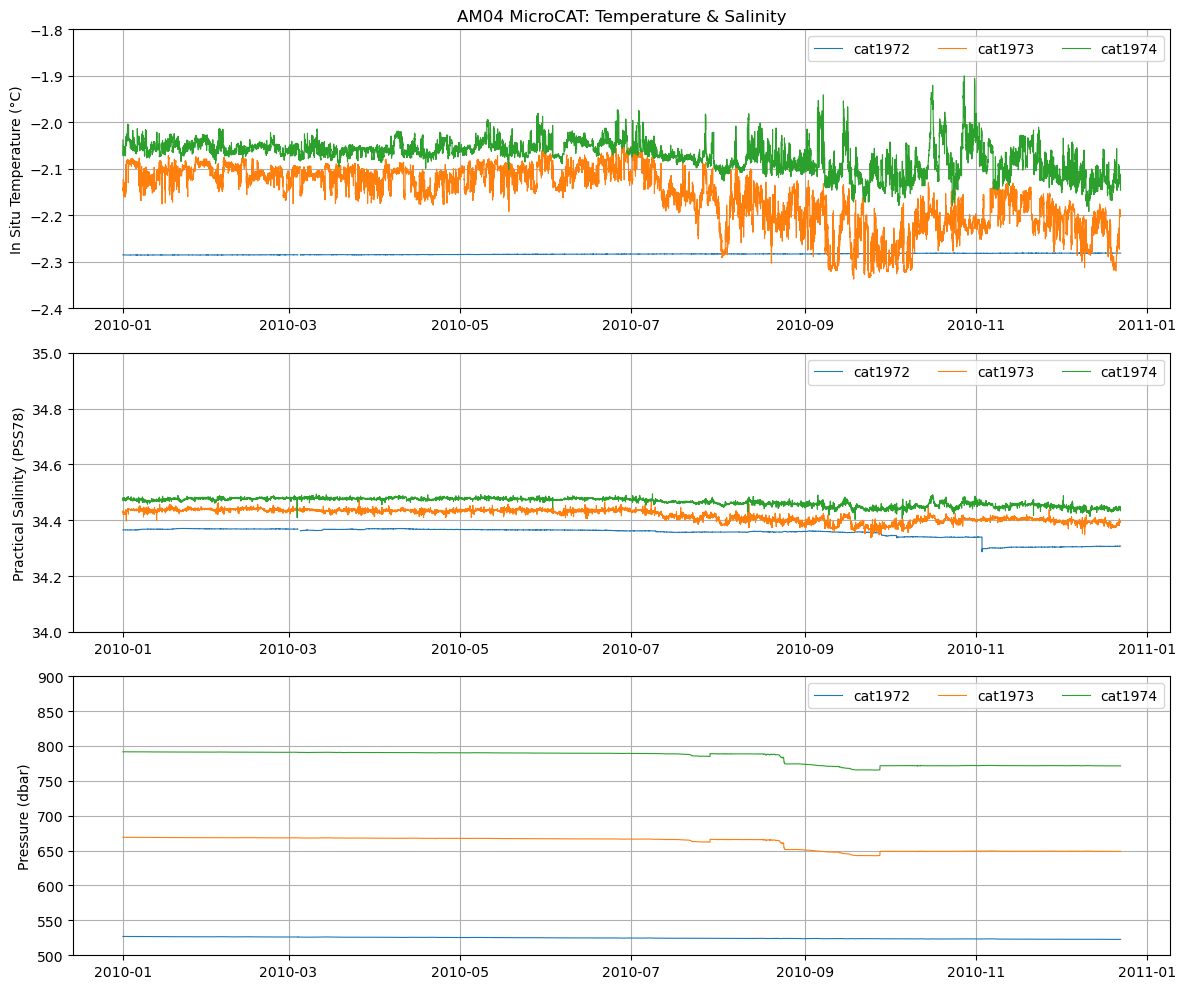

In [14]:
bh = "AM04"

for year in df[df["borehole"] == bh]["time"].dt.year.unique():
    plot_time_series(df, bh, (-2.4, -1.8), (34, 35), (500, 900), year)

### Add Pressure Events

In [15]:
# June-July 2008 transient pressure change event
events.append({"borehole": bh, "event_start": "2008-06-25 00:30:00", "transition_end": "2008-06-27 04:00:00", "event_end": "2008-07-07 11:30:00", "reversion": True, "notes": "clear impact on T", "decision": "1"})

# May-June 2009 transient pressure change event
events.append({"borehole": bh, "event_start": "2009-05-31 10:30:00", "transition_end": "2009-06-04 01:30:00", "event_end": "2009-06-04 05:30:00", "reversion": True, "notes": "very minor impact on T", "decision": "1"})

# July 2009 permanent pressure change event
events.append({"borehole": bh, "event_start": "2009-07-08 08:30:00", "transition_end": "2009-07-11 19:30:00", "event_end": np.nan, "reversion": False, "notes": "permanent impact on T, and eventually S", "decision": "2"})

# July 2010 transient pressure change event
events.append({"borehole": bh, "event_start": "2010-07-16 07:30:00", "transition_end": "2010-07-25 11:30:00", "event_end": "2010-07-29 05:00:00", "reversion": True, "notes": "already permanently encased", "decision": "2"})

# August-September 2010 permanent (w/ semi-transient portion) pressure change event
events.append({"borehole": bh, "event_start": "2010-08-20 23:00:00", "transition_end": "2010-09-19 06:00:00", "event_end": "2010-09-27 17:00:00", "reversion": True, "notes": "already permanently encased", "decision": "2"})

## AM05

### Visually Inspect CTD Changes

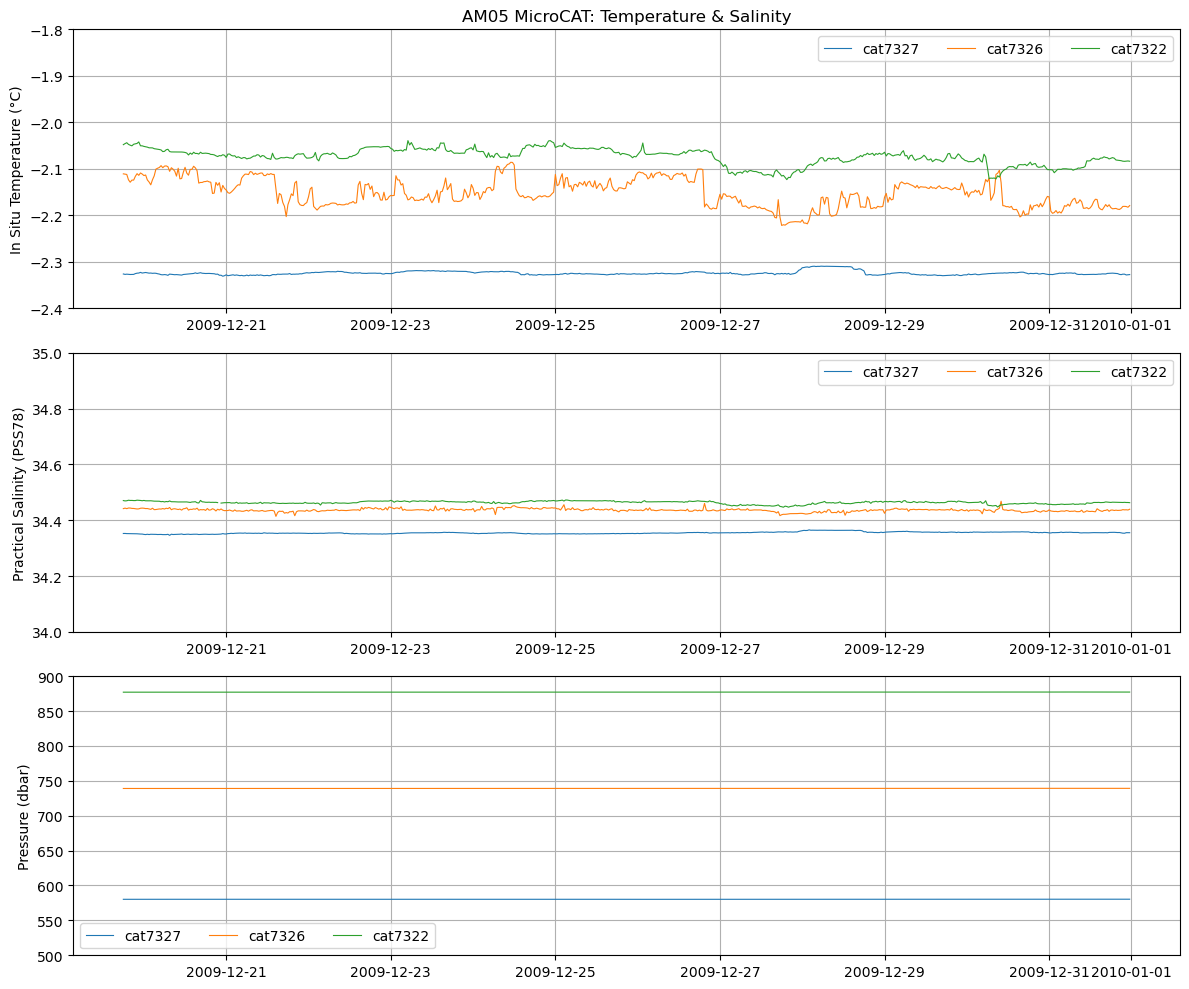

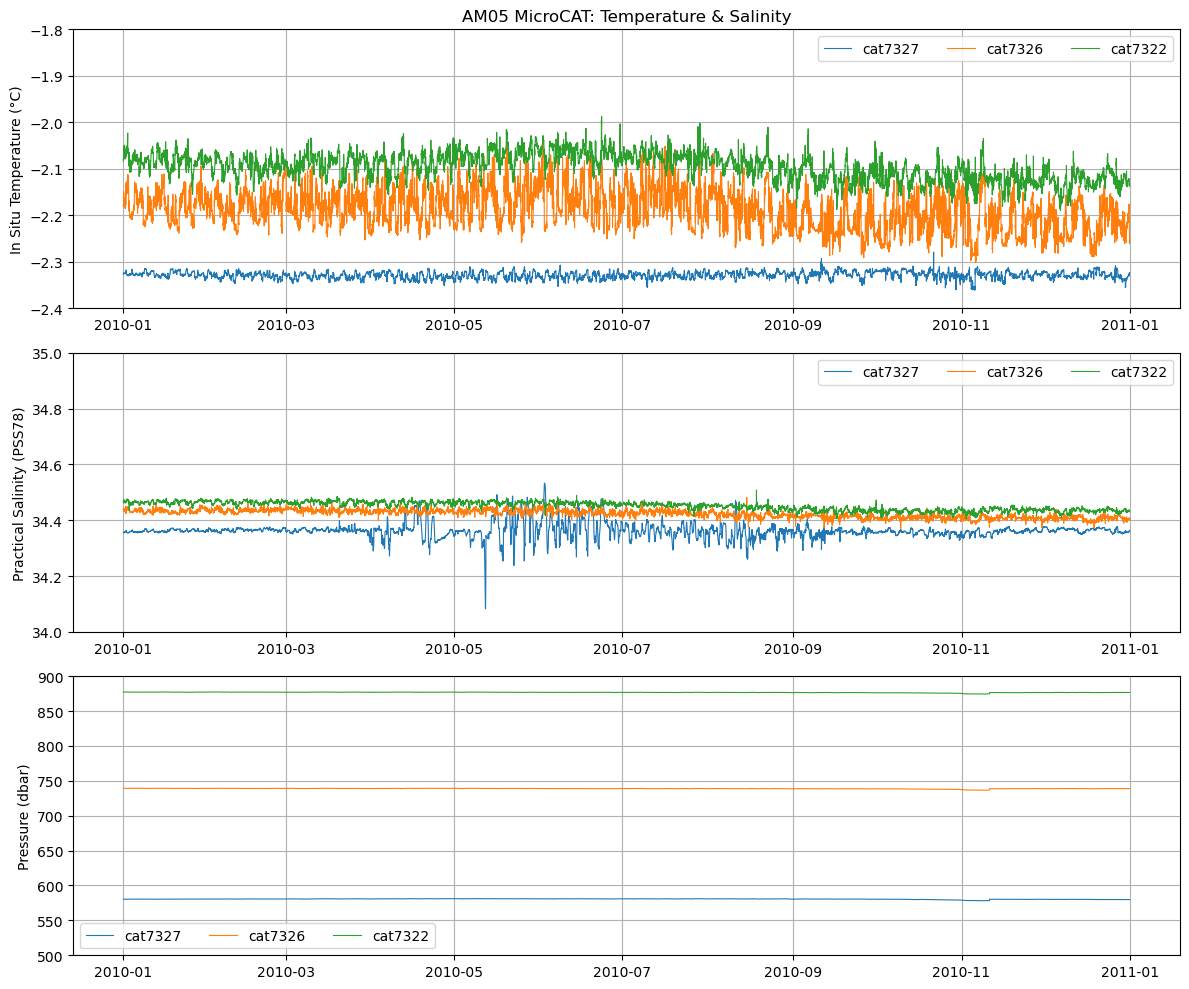

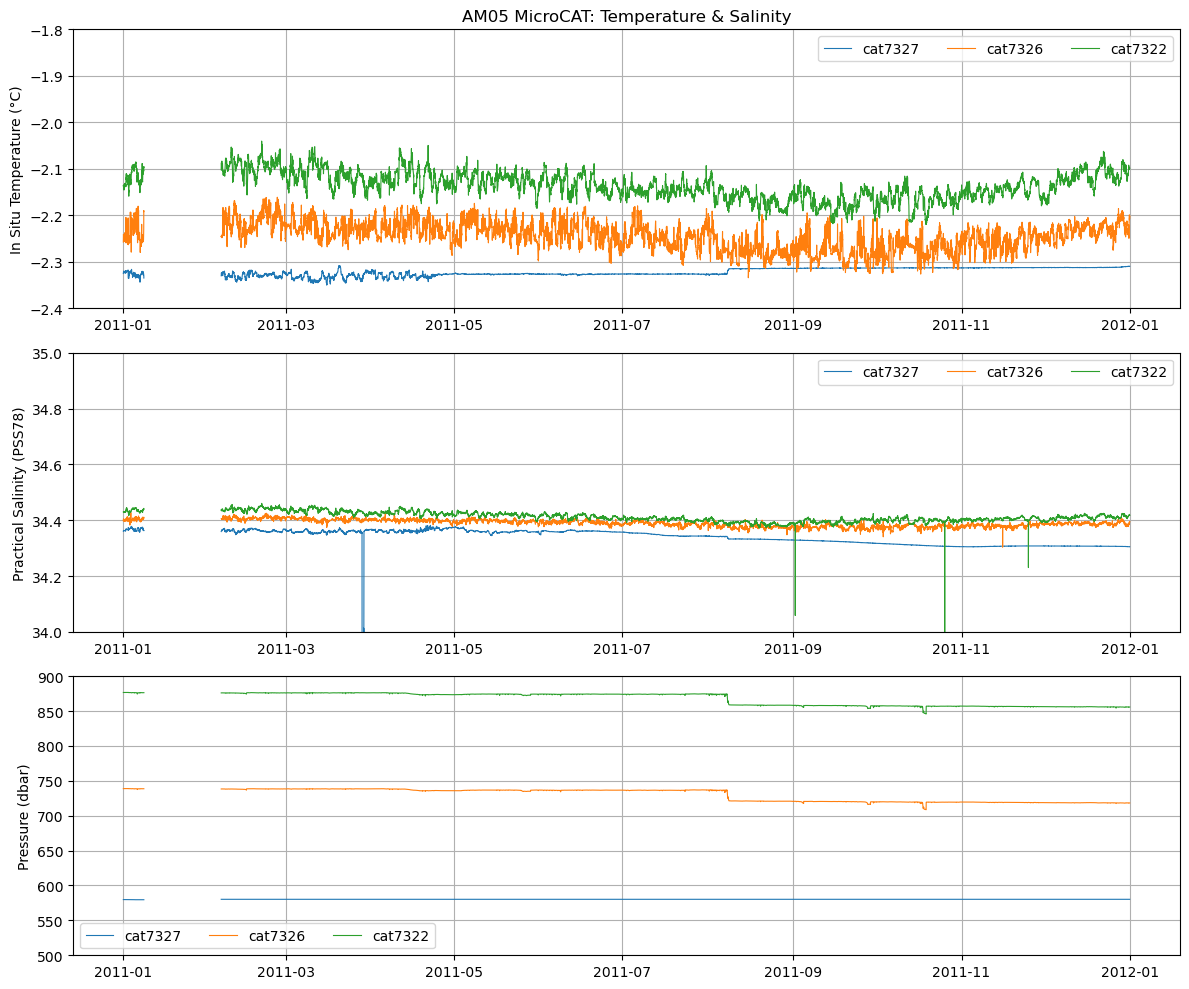

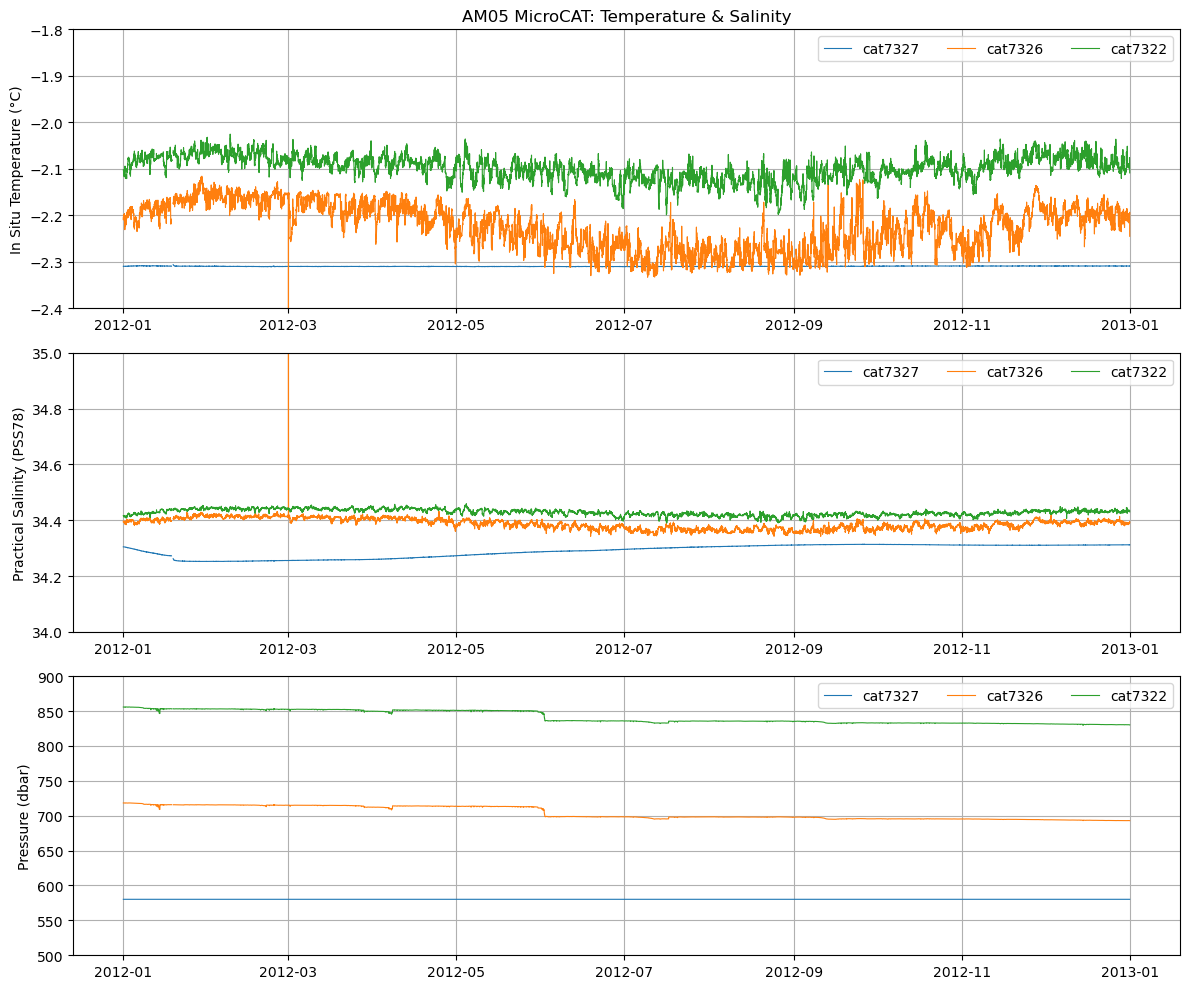

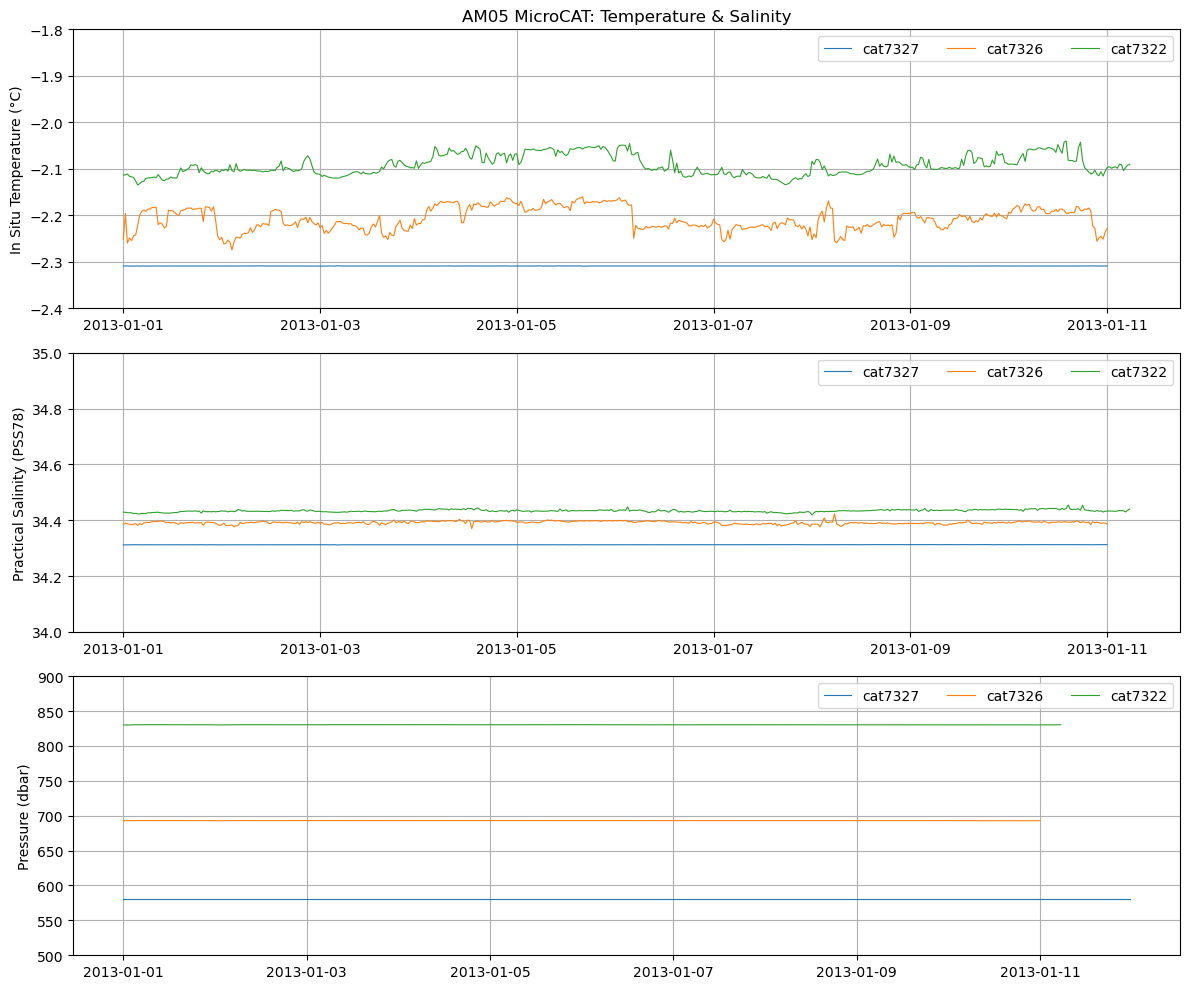

In [16]:
bh = "AM05"

for year in df[df["borehole"] == bh]["time"].dt.year.unique():
    plot_time_series(df, bh, (-2.4, -1.8), (34, 35), (500, 900), year)

### Add Pressure Events

In [17]:
# October-November 2010 transient pressure change event
events.append({"borehole": bh, "event_start": "2010-10-30 11:00:00", "transition_end": "2010-11-09 00:30:00", "event_end": "2010-11-11 04:00:00", "reversion": True, "notes": "no evident impact", "decision": "0"})

# April 2011 permanent pressure change event
events.append({"borehole": bh, "event_start": "2011-04-13 08:00:00", "transition_end": "2011-04-18 12:00:00", "event_end": np.nan, "reversion": True, "notes": "permanent impact on T, S", "decision": "2"})

# August 2011 permanent pressure change event
events.append({"borehole": bh, "event_start": "2011-08-01 09:30:00", "transition_end": "2011-08-08 19:30:00", "event_end": np.nan, "reversion": False, "notes": "permanent impact on T, S", "decision": "2"})

# October 2011 transient pressure change event
events.append({"borehole": bh, "event_start": "2011-10-14 22:30:00", "transition_end": "2011-10-19 03:00:00", "event_end": "2011-10-19 08:00:00", "reversion": True, "notes": "no evident impact", "decision": "2"})

# May-June 2012 permanent pressure change event
events.append({"borehole": bh, "event_start": "2012-05-30 05:00:00", "transition_end": "2012-06-02 10:00:00", "event_end": np.nan, "reversion": False, "notes": "no evident impact", "decision": "2"})

## Collate and Handle Pressure Events

### Add Pressure Events into DataFrame

In [18]:
events_df = pd.DataFrame(events)

events_df["event_start"] = pd.to_datetime(events_df["event_start"])
events_df["transition_end"] = pd.to_datetime(events_df["transition_end"])
events_df["event_end"] = pd.to_datetime(events_df["event_end"])

events_df["transition_time"] = (events_df["transition_end"] - events_df["event_start"]).dt.total_seconds() / (3600 * 24) # in days
events_df["duration"] = (events_df["event_end"] - events_df["event_start"]).dt.total_seconds() / (3600 * 24) # in days

events_df["decision"] = events_df["decision"].astype(int)

def calculate_pressure_change(row, df):
    # Filter the original dataframe to the time range of the event for the specific borehole
    mask = ((df["borehole"] == row["borehole"]) & (df["time"] >= row["event_start"]) & (df["time"] <= row["transition_end"]))
    # Apply the mask to get the relevant subset of data
    df_sub = df[mask].copy()

    # Initialise a list to store the max pressure change for each cat
    changes = []
    # Iterate over each cat in the borehole
    for cat in df_sub["cat"].unique():
        # Filter the subset to the current cat
        df_cat = df_sub[df_sub["cat"] == cat]["pressure"]
        # Calculate the pressure change as the difference between the max and min pressure during the event
        changes.append(df_cat.max() - df_cat.min())
    # Return the minimum pressure change across all cats for the event, or NaN if there are no cats
    return np.median(changes) if changes else np.nan

events_df["pressure_change"] = events_df.apply(calculate_pressure_change, axis=1, df=df)

print(events_df)    

   borehole         event_start      transition_end           event_end  \
0      AM01 2002-02-03 00:00:00 2002-02-12 00:00:00 2002-02-12 00:00:00   
1      AM01 2002-04-27 00:00:00 2002-04-29 00:00:00 2002-04-29 00:00:00   
2      AM01 2002-06-07 00:00:00 2002-06-09 00:00:00 2002-06-09 00:00:00   
3      AM01 2003-04-05 00:00:00 2003-04-10 00:00:00 2003-04-21 00:00:00   
4      AM01 2003-04-27 00:00:00 2003-04-29 00:00:00 2003-05-08 00:00:00   
5      AM01 2003-05-25 00:00:00 2003-05-30 00:00:00                 NaT   
6      AM04 2008-06-25 00:30:00 2008-06-27 04:00:00 2008-07-07 11:30:00   
7      AM04 2009-05-31 10:30:00 2009-06-04 01:30:00 2009-06-04 05:30:00   
8      AM04 2009-07-08 08:30:00 2009-07-11 19:30:00                 NaT   
9      AM04 2010-07-16 07:30:00 2010-07-25 11:30:00 2010-07-29 05:00:00   
10     AM04 2010-08-20 23:00:00 2010-09-19 06:00:00 2010-09-27 17:00:00   
11     AM05 2010-10-30 11:00:00 2010-11-09 00:30:00 2010-11-11 04:00:00   
12     AM05 2011-04-13 08

### Remove Upper MicroCAT CTD Data Depending on Decision

In [19]:
# Initialise a dictionary to store the upper cat for each borehole
upper_cats = {}
# Iterate over each unique borehole in the dataframe
for bh in df["borehole"].unique():
    # Filter the dataframe to the current borehole
    bh_data = df[df["borehole"] == bh]
    # Calculate the median pressure for each cat within the borehole
    medians = bh_data.groupby("cat")["pressure"].median()
    # Identify the cat with the minimum median pressure and assign it as the upper cat for the borehole
    upper_cats[bh] = medians.idxmin()

df_pressure_changes = df.copy()

# We will want to replace data in all columns except for time, borehole, and cat with NaNs
# First, we establish which columns to replace
columns_to_replace = [c for c in df_pressure_changes.columns if c not in ["time", "borehole", "cat", "pressure", "AM", "source_file", "latitude", "longitude", "water_column_position"]]

# Iterate over each event
for _, event in events_df.iterrows():
    # Extract the borehole corresponding to the event
    bh = event["borehole"]
    # Extract the decision for the event
    decision = event["decision"]
    # Extract the upper cat for the particular borehole
    upper_cat = upper_cats[bh]

    # If decision is 0, do nothing (keep all data)
    if decision == 0:
        continue

    # If decision is 1, remove all upper cat data between event_start and event_end
    elif decision == 1:
        # Create a mask to identify rows corresponding to the upper cat and time range of the event
        mask = (
            (df_pressure_changes["borehole"] == bh) &
            (df_pressure_changes["cat"] == upper_cat) &
            (df_pressure_changes["time"] >= event["event_start"]) &
            (df_pressure_changes["time"] <= event["event_end"])
        )
        # Remove the identified rows from the dataframe
        df_pressure_changes.loc[mask, columns_to_replace] = np.nan

    # If decision is 2, remove all upper cat data from event_start onwards
    elif decision == 2:
        mask = (
            (df_pressure_changes["borehole"] == bh) &
            (df_pressure_changes["cat"] == upper_cat) &
            (df_pressure_changes["time"] >= event["event_start"])
        )
        df_pressure_changes.loc[mask, columns_to_replace] = np.nan


### Check Removal

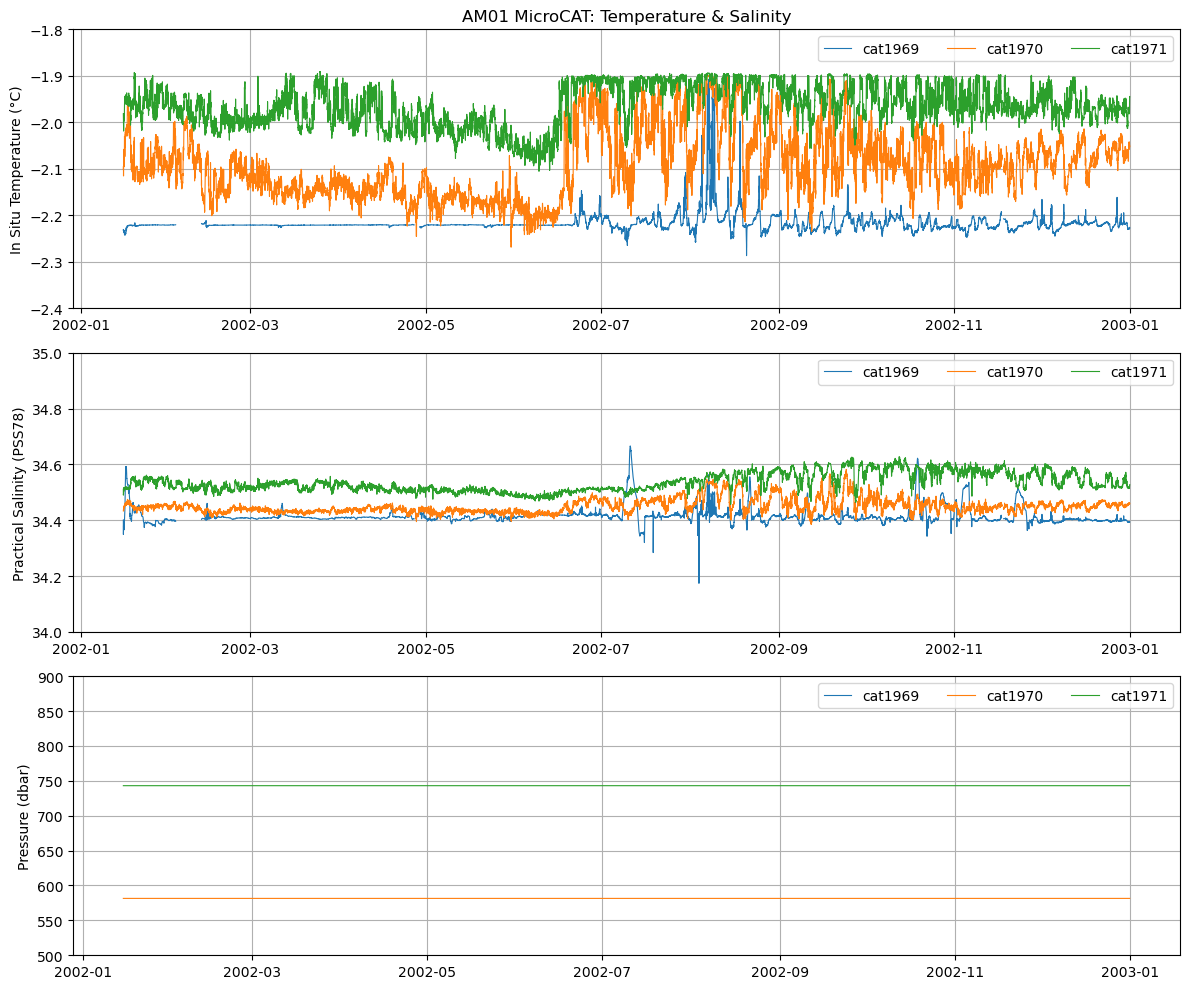

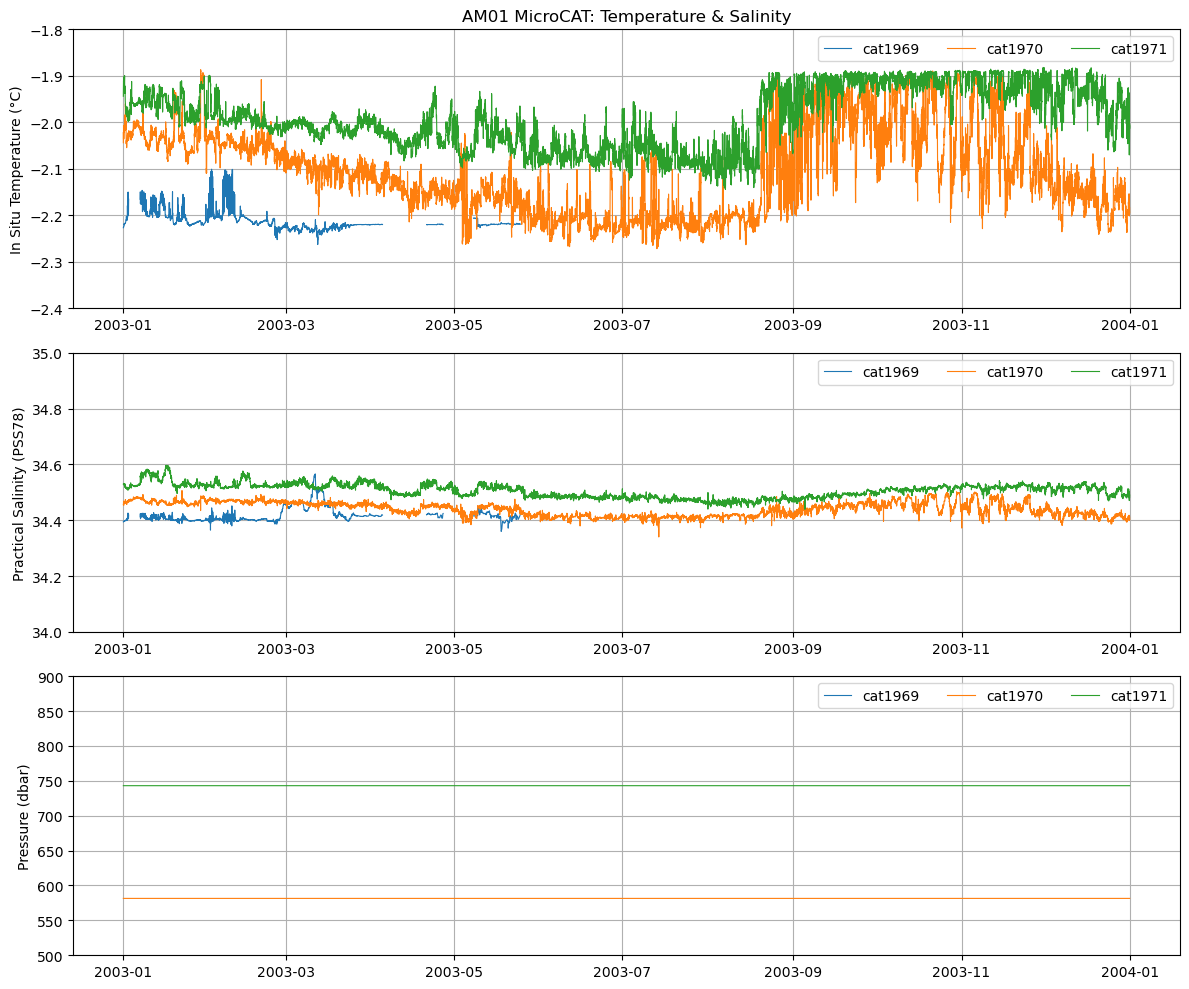

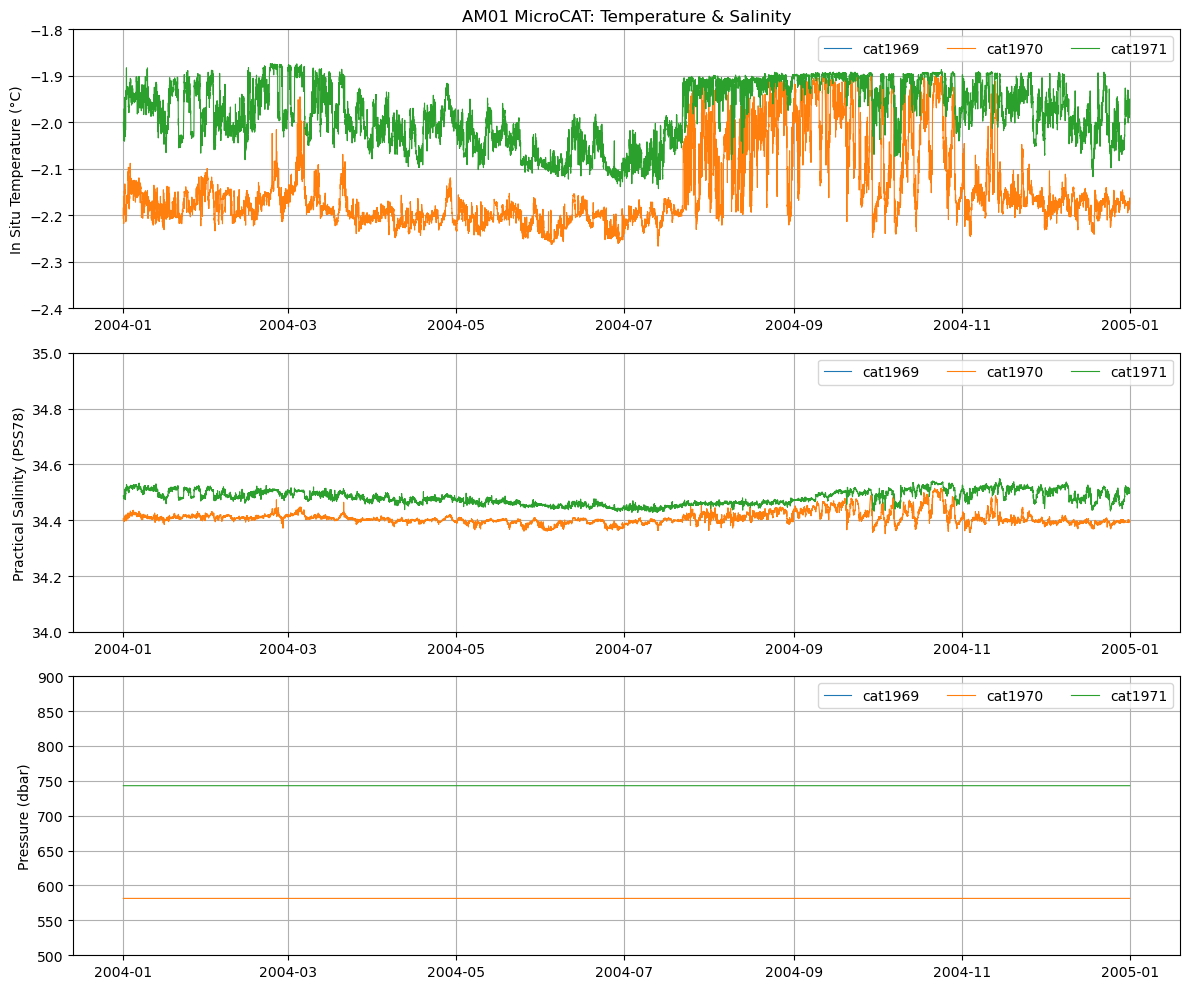

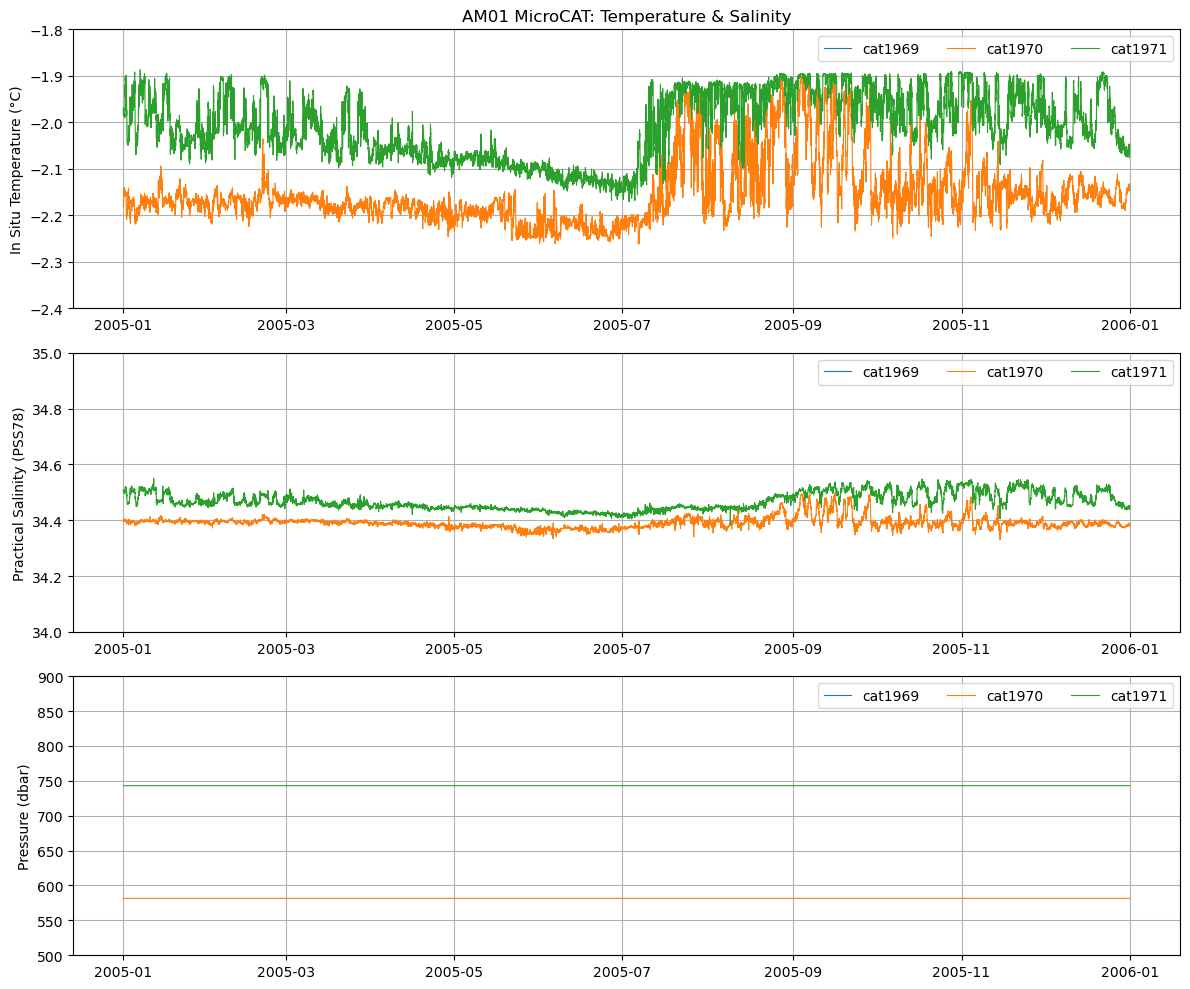

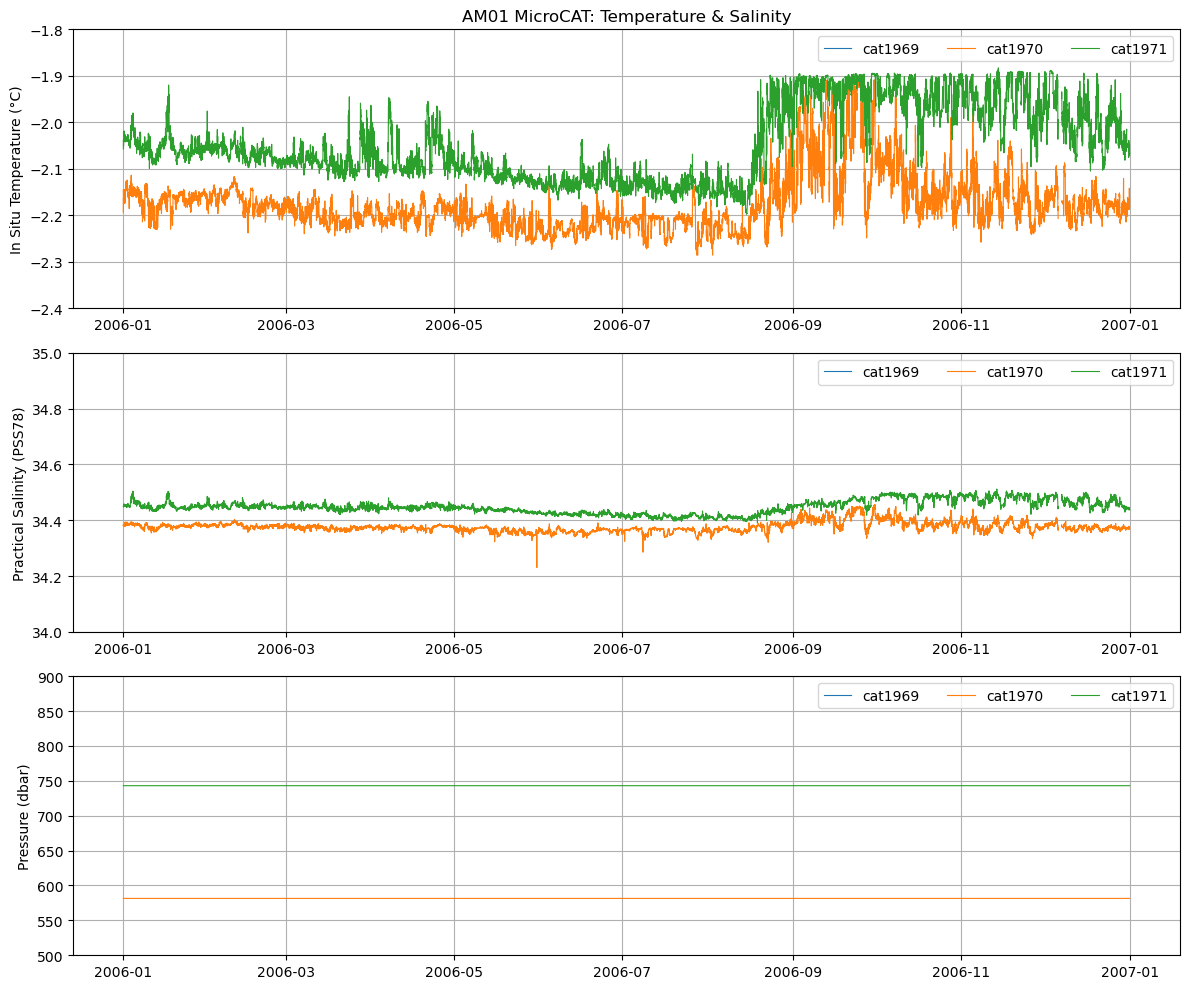

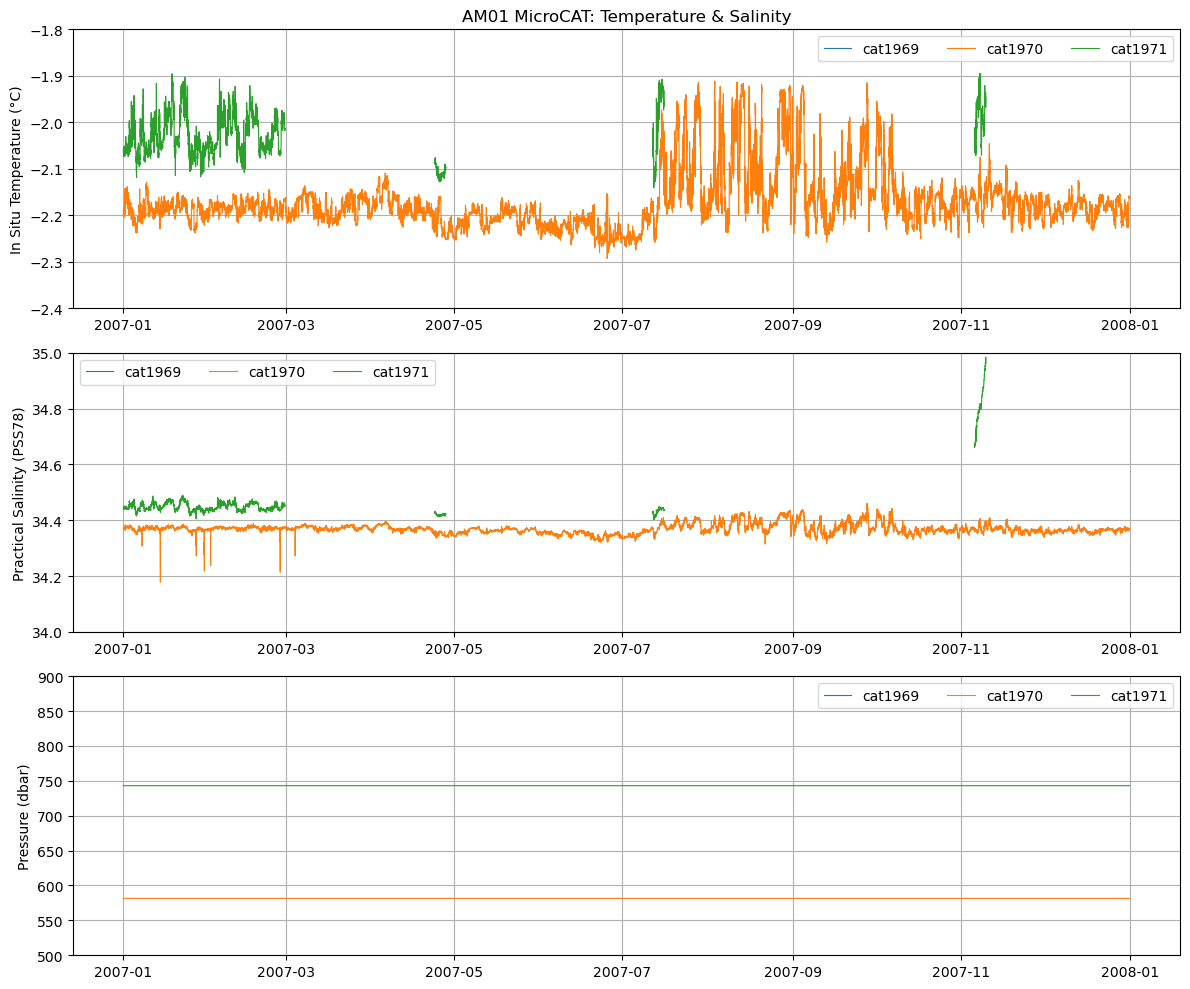

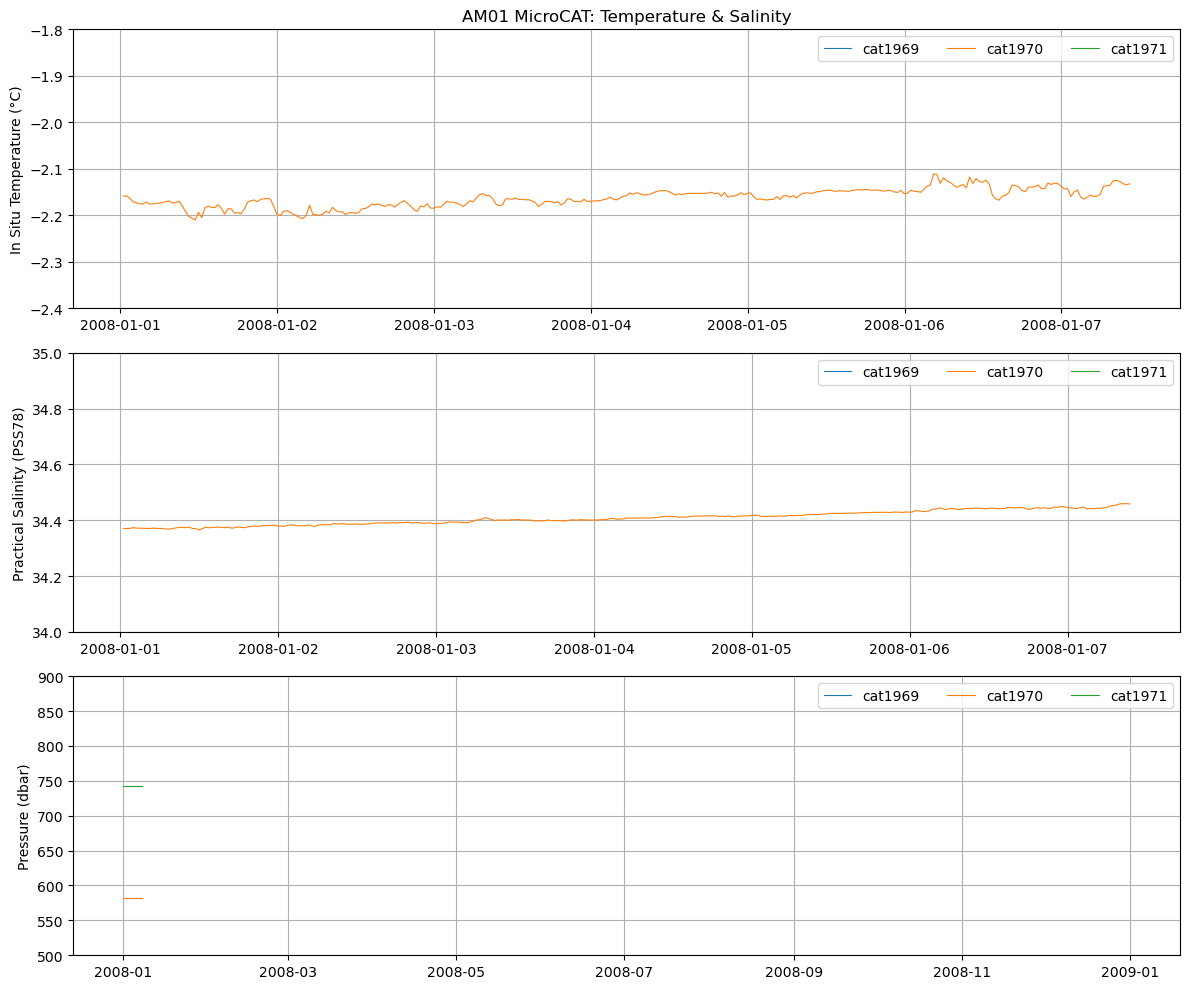

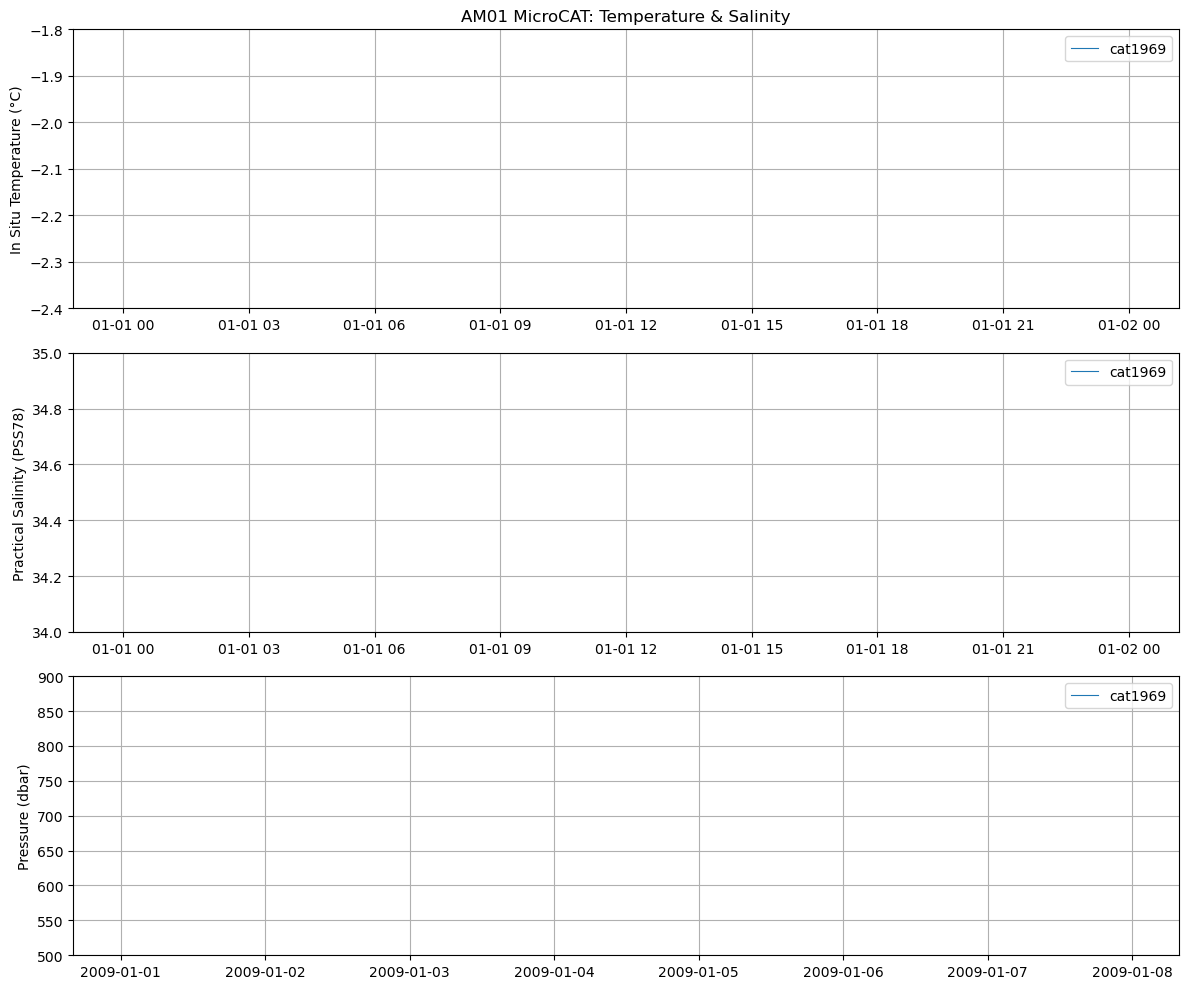

In [20]:
bh = "AM01"

for year in df_pressure_changes[df_pressure_changes["borehole"] == bh]["time"].dt.year.unique():
    plot_time_series(df_pressure_changes, bh, (-2.4, -1.8), (34, 35), (500, 900), year)

### Save Dataframe as Parquet

In [21]:
# Save to parquet file for efficient storage and future use
# Note: parquet is a columnar storage format that is more efficient for large datasets and preserves data types better than CSV
# Note: parquet files can be read back into pandas with pd.read_parquet("data/proc/03_pressure_handled.parquet")
# Note: this will overwrite any existing file at this location
df_pressure_changes.to_parquet("/g/data/gv90/ad6790/amery-amisor/data/proc/03_pressure_handled.parquet", index=False)